In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import linear_model
import joblib

In [2]:
data = pd.read_csv("telecom_customer_churn.csv")
zipcode = pd.read_csv("telecom_zipcode_population.csv")

In [3]:
data.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [4]:
zipcode.head()

,Zip Code,Population
0,90001,54492
1,90002,44586
2,90003,58198
3,90004,67852
4,90005,43019


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   str    
 1   Gender                             7043 non-null   str    
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   str    
 4   Number of Dependents               7043 non-null   int64  
 5   City                               7043 non-null   str    
 6   Zip Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number of Referrals                7043 non-null   int64  
 10  Tenure in Months                   7043 non-null   int64  
 11  Offer                              3166 non-null   str    
 12  Pho

In [6]:
print(data["Customer Status"].count().sum())
print(data["Customer Status"].unique())
print(data['Customer Status'].value_counts())

7043
<StringArray>
['Stayed', 'Churned', 'Joined']
Length: 3, dtype: str
Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64


In [7]:
data["Offer"].value_counts()

Offer
Offer B    824
Offer E    805
Offer D    602
Offer A    520
Offer C    415
Name: count, dtype: int64

In [8]:
data = data.merge(zipcode, on='Zip Code', how='left')
data.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason,Population
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN,4498
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN,31297
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices,62069
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction,46677
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability,42853


In [9]:
droped = ['Customer ID','Longitude','Latitude','Zip Code','Total Charges','Total Refunds','Total Extra Data Charges','Total Long Distance Charges']

In [10]:
data.drop(droped,axis=1,inplace=True)

In [11]:
data.head()

,Gender,Age,Married,Number of Dependents,City,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,...,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Revenue,Customer Status,Churn Category,Churn Reason,Population
0,Female,37,Yes,0,Frazier Park,2,9,NaN,Yes,42.39,...,Yes,One Year,Yes,Credit Card,65.6,974.81,Stayed,NaN,NaN,4498
1,Male,46,No,0,Glendale,0,9,NaN,Yes,10.69,...,No,Month-to-Month,No,Credit Card,-4.0,610.28,Stayed,NaN,NaN,31297
2,Male,50,No,0,Costa Mesa,0,4,Offer E,Yes,33.65,...,Yes,Month-to-Month,Yes,Bank Withdrawal,73.9,415.45,Churned,Competitor,Competitor had better devices,62069
3,Male,78,Yes,0,Martinez,1,13,Offer D,Yes,27.82,...,Yes,Month-to-Month,Yes,Bank Withdrawal,98.0,1599.51,Churned,Dissatisfaction,Product dissatisfaction,46677
4,Female,75,Yes,0,Camarillo,3,3,NaN,Yes,7.38,...,Yes,Month-to-Month,Yes,Credit Card,83.9,289.54,Churned,Dissatisfaction,Network reliability,42853


In [12]:
x = data.drop(columns=['Customer Status'])
x.head()

,Gender,Age,Married,Number of Dependents,City,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,...,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Revenue,Churn Category,Churn Reason,Population
0,Female,37,Yes,0,Frazier Park,2,9,NaN,Yes,42.39,...,No,Yes,One Year,Yes,Credit Card,65.6,974.81,NaN,NaN,4498
1,Male,46,No,0,Glendale,0,9,NaN,Yes,10.69,...,Yes,No,Month-to-Month,No,Credit Card,-4.0,610.28,NaN,NaN,31297
2,Male,50,No,0,Costa Mesa,0,4,Offer E,Yes,33.65,...,No,Yes,Month-to-Month,Yes,Bank Withdrawal,73.9,415.45,Competitor,Competitor had better devices,62069
3,Male,78,Yes,0,Martinez,1,13,Offer D,Yes,27.82,...,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.0,1599.51,Dissatisfaction,Product dissatisfaction,46677
4,Female,75,Yes,0,Camarillo,3,3,NaN,Yes,7.38,...,No,Yes,Month-to-Month,Yes,Credit Card,83.9,289.54,Dissatisfaction,Network reliability,42853


In [13]:
y = data["Customer Status"]
y.head()

0     Stayed
1     Stayed
2    Churned
3    Churned
4    Churned
Name: Customer Status, dtype: str

In [14]:
gen = pd.get_dummies(x['Gender'],drop_first=True,dtype='uint8')
gen.head()

,Male
0,0
1,1
2,1
3,1
4,0


count    7043.000000
mean       46.509726
std        16.750352
min        19.000000
25%        32.000000
50%        46.000000
75%        60.000000
max        80.000000
Name: Age, dtype: float64


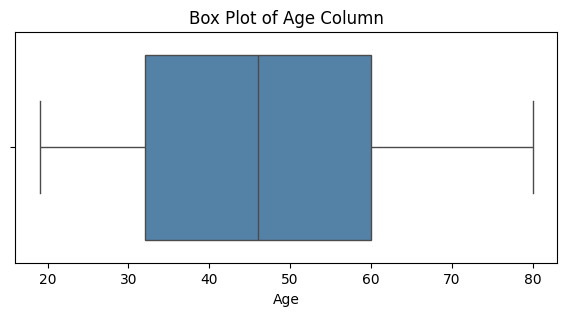

In [15]:
# Print exact summary stats (min, 25%, 50% median, 75%, max)
print(x['Age'].describe())

# Plot the single column
plt.figure(figsize=(7, 3))
sns.boxplot(x=x['Age'], color='steelblue')
plt.title('Box Plot of Age Column')
plt.xlabel('Age')
plt.show()


In [16]:
x['Age'].skew()

np.float64(0.1621864486741778)

In [17]:
x['Age'] = x['Age'].astype('uint8')
x['Age'].dtype

dtype('uint8')

In [18]:
mar = pd.get_dummies(x['Married'],drop_first=True,dtype='uint8')
mar.head()

,Yes
0,1
1,0
2,0
3,1
4,1


<Axes: ylabel='Number of Dependents'>

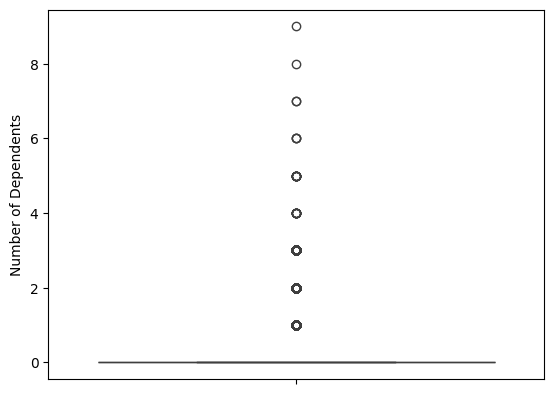

In [19]:
sns.boxplot(x['Number of Dependents'])

In [20]:
df = data[data['Customer Status'] != 'Joined'].copy()
df['Churn'] = (df['Customer Status'] == 'Churned').astype(int)

df['Has Dependents'] = (df['Number of Dependents'] > 0).map({True: 'Yes', False: 'No'})

print("Average dependents by Married:")
print(df.groupby('Married')['Number of Dependents'].mean().round(2))

print("\nCounts (Married vs Has Dependents):")
print(pd.crosstab(df['Married'], df['Has Dependents']))

print("\nRow percentages:")
print(pd.crosstab(df['Married'], df['Has Dependents'], normalize='index').round(2) * 100)

print("\nChurn rate (%) by Married and Has Dependents:")
print((df.groupby(['Married', 'Has Dependents'])['Churn'].mean() * 100).round(1))

Average dependents by Married:
Married
No     0.16
Yes    0.79
Name: Number of Dependents, dtype: float64

Counts (Married vs Has Dependents):
Has Dependents    No   Yes
Married                   
No              3011   260
Yes             2031  1287

Row percentages:
Has Dependents    No   Yes
Married                   
No              92.0   8.0
Yes             61.0  39.0

Churn rate (%) by Married and Has Dependents:
Married  Has Dependents
No       No                38.2
         Yes               19.2
Yes      No                30.2
         Yes                4.4
Name: Churn, dtype: float64


In [21]:
mar['Yes'].corr(x['Number of Dependents'])

np.float64(0.3242051367512027)

In [22]:
x['Number of Dependents'] = x['Number of Dependents'].astype('uint8')
x['Number of Dependents'].dtype

dtype('uint8')

In [23]:
x['City'].isna().sum()

np.int64(0)

In [24]:
x.drop(['City'],axis=1,inplace=True)

In [25]:
# Average Population for churned vs stayed (Joined customers excluded)
df = data[data['Customer Status'] != 'Joined']

print(df.groupby('Customer Status')['Population'].mean().round(0))

Customer Status
Churned    23957.0
Stayed     21388.0
Name: Population, dtype: float64


In [26]:
x['Number of Referrals'].skew()

np.float64(1.4460596247412694)

In [27]:
x['Number of Referrals'] = x['Number of Referrals'].astype('uint8')

<Axes: ylabel='Tenure in Months'>

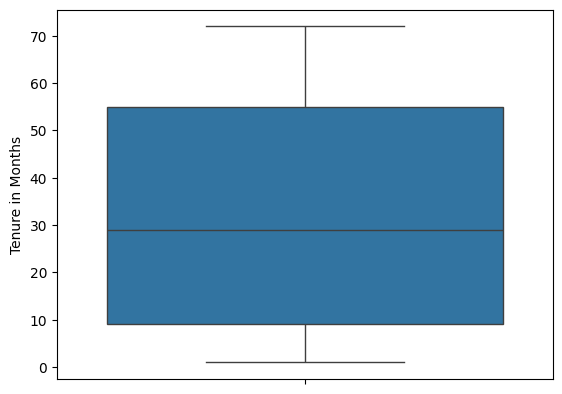

In [28]:
sns.boxplot(x['Tenure in Months'])

In [29]:
x['Tenure in Months'] = x['Tenure in Months'].astype('uint8')

In [30]:
x['Offer'].value_counts(dropna=0)

Offer
NaN        3877
Offer B     824
Offer E     805
Offer D     602
Offer A     520
Offer C     415
Name: count, dtype: int64

In [31]:
x['Offer'] = x['Offer'].fillna("No offer",axis=0)
x['Offer'].unique()

<StringArray>
['No offer', 'Offer E', 'Offer D', 'Offer A', 'Offer B', 'Offer C']
Length: 6, dtype: str

<Axes: ylabel='Offer'>

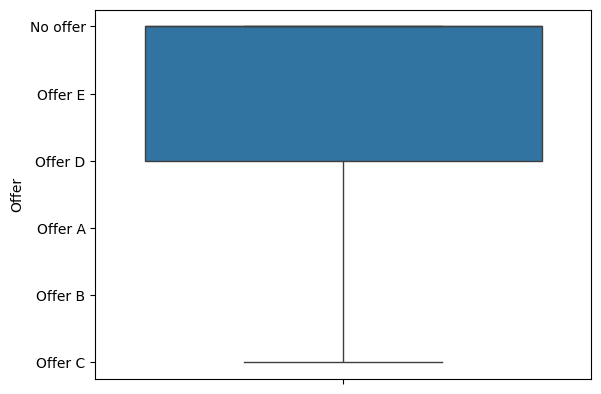

In [36]:
sns.boxplot(x["Offer"])

In [43]:
off = pd.get_dummies(x["Offer"],drop_first=True,dtype='uint8')
off.head()

,Offer A,Offer B,Offer C,Offer D,Offer E
0,0,0,0,0,0
1,0,0,0,0,0
2,0,0,0,0,1
3,0,0,0,1,0
4,0,0,0,0,0


In [48]:
x['Phone Service'] = x['Phone Service'].map({'Yes':1 , 'No':0})
x['Phone Service'].head()

0    1
1    1
2    1
3    1
4    1
Name: Phone Service, dtype: int64

In [50]:
x['Phone Service'] = x['Phone Service'].astype('uint8')
x['Phone Service'].head()

0    1
1    1
2    1
3    1
4    1
Name: Phone Service, dtype: uint8

<Axes: ylabel='Avg Monthly Long Distance Charges'>

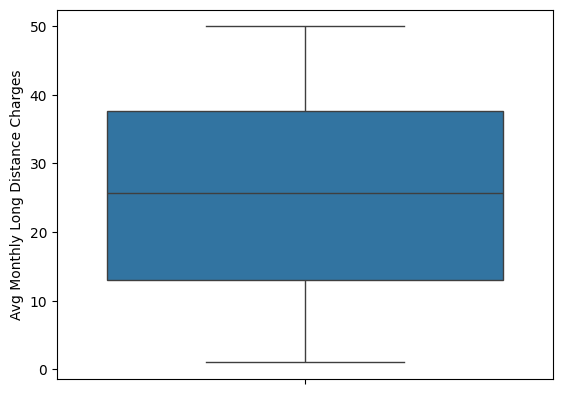

In [57]:
sns.boxplot(x['Avg Monthly Long Distance Charges'])

In [66]:
x['Avg Monthly Long Distance Charges'] = x['Avg Monthly Long Distance Charges'].fillna(0)

In [74]:
x['Avg Monthly Long Distance Charges']=x['Avg Monthly Long Distance Charges'].astype('float32')
x['Avg Monthly Long Distance Charges'].dtype

dtype('float32')

In [78]:
x['Multiple Lines'] = x['Multiple Lines'].fillna('No phones',axis=0)
x['Multiple Lines'].unique()

<StringArray>
['No', 'Yes', 'No phones']
Length: 3, dtype: str

In [83]:
mul = pd.get_dummies(x['Multiple Lines'],drop_first=True,dtype='uint8')
mul.head()

,No phones,Yes
0,0,0
1,0,1
2,0,0
3,0,0
4,0,0


In [97]:
x['Internet Service'] = x['Internet Service'].map({"Yes":1,"No":0}).astype('uint8')
x['Internet Service'].dtype

dtype('uint8')

In [105]:
x["Internet Type"] = x["Internet Type"].fillna('No Internet')
x["Internet Type"].unique()

<StringArray>
['Cable', 'Fiber Optic', 'DSL', 'No Internet']
Length: 4, dtype: str

In [108]:
inty = pd.get_dummies(x["Internet Type"],drop_first=True,dtype='uint8')
inty["No Internet"].dtype
inty["No Internet"].head()

0    0
1    0
2    0
3    0
4    0
Name: No Internet, dtype: uint8

In [117]:
x['Avg Monthly GB Download'] = x['Avg Monthly GB Download'].fillna(0)
col = 'Avg Monthly GB Download'

# 1. No blanks left? (should print 0)
print("Blanks:", x[col].isna().sum())

# 2. Any value with decimals? (should print 0)
print("With decimals:", (x[col] != x[col].round()).sum())

# 3. Inside the uint8 range of 0 to 255? (should print 0 and a max below 255)
print("Below 0:", (x[col] < 0).sum())
print("Max value:", x[col].max())

Blanks: 0
With decimals: 0
Below 0: 0
Max value: 85.0


In [119]:
x['Avg Monthly GB Download'] = x['Avg Monthly GB Download'].astype('uint8')
x['Avg Monthly GB Download'].dtype

dtype('uint8')

In [128]:
x['Online Security'] = x['Online Security'].fillna("No Service")
onse = pd.get_dummies(x['Online Security'],drop_first=True,dtype='uint8')
onse['Yes'].head()

0    0
1    0
2    0
3    0
4    0
Name: Yes, dtype: uint8

In [153]:
x.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 29 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             7043 non-null   str    
 1   Age                                7043 non-null   uint8  
 2   Married                            7043 non-null   str    
 3   Number of Dependents               7043 non-null   uint8  
 4   Number of Referrals                7043 non-null   uint8  
 5   Tenure in Months                   7043 non-null   uint8  
 6   Offer                              7043 non-null   str    
 7   Phone Service                      7043 non-null   uint8  
 8   Avg Monthly Long Distance Charges  7043 non-null   float32
 9   Multiple Lines                     7043 non-null   str    
 10  Internet Service                   7043 non-null   uint8  
 11  Internet Type                      7043 non-null   str    
 12  Avg

In [131]:
x['Online Backup'] = x['Online Backup'].fillna("No Service")
onbp = pd.get_dummies(x['Online Backup'],drop_first=True,dtype='uint8')

,No Service,Yes
0,0,1
1,0,0
2,0,0
3,0,1
4,0,0
...,...,...
7038,0,0
7039,0,0
7040,0,1
7041,0,0


In [133]:
onbp.drop('No Service',inplace=True,axis=1)
onbp

,Yes
0,1
1,0
2,0
3,1
4,0
...,...
7038,0
7039,0
7040,1
7041,0


In [138]:
x['Device Protection Plan'] = x['Device Protection Plan'].fillna("No Service")
dpp = pd.get_dummies(x['Device Protection Plan'],drop_first=True,dtype='uint8')
dpp.drop('No Service',inplace=True,axis=1)
dpp

,Yes
0,0
1,0
2,1
3,1
4,0
...,...
7038,0
7039,0
7040,0
7041,1


In [140]:
x['Premium Tech Support'] = x['Premium Tech Support'].fillna("No Service")
pts = pd.get_dummies(x['Premium Tech Support'],drop_first=True,dtype='uint8')
pts.drop('No Service',inplace=True,axis=1)
pts

,Yes
0,1
1,0
2,0
3,0
4,1
...,...
7038,1
7039,0
7040,0
7041,1


In [143]:
x['Streaming TV'] = x['Streaming TV'].fillna("No Service")
stv = pd.get_dummies(x['Streaming TV'],drop_first=True,dtype='uint8')
stv.drop('No Service',inplace=True,axis=1)
stv

,Yes
0,1
1,0
2,0
3,1
4,1
...,...
7038,0
7039,0
7040,0
7041,0


In [144]:
x['Streaming Movies'] = x['Streaming Movies'].fillna("No Service")
smo = pd.get_dummies(x['Streaming Movies'],drop_first=True,dtype='uint8')
smo.drop('No Service',inplace=True,axis=1)
smo

,Yes
0,0
1,1
2,0
3,1
4,0
...,...
7038,0
7039,1
7040,0
7041,1


In [145]:
x['Streaming Music'] = x['Streaming Music'].fillna("No Service")
sm = pd.get_dummies(x['Streaming Music'],drop_first=True,dtype='uint8')
sm.drop('No Service',inplace=True,axis=1)
sm

,Yes
0,0
1,1
2,0
3,0
4,0
...,...
7038,1
7039,1
7040,0
7041,1


In [146]:
x['Unlimited Data'] = x['Unlimited Data'].fillna("No Service")
um = pd.get_dummies(x['Unlimited Data'],drop_first=True,dtype='uint8')
um.drop('No Service',inplace=True,axis=1)
um

,Yes
0,1
1,0
2,1
3,1
4,1
...,...
7038,1
7039,1
7040,1
7041,1


In [151]:
con = pd.get_dummies(x['Contract'],drop_first=True,dtype='uint8')
con

,One Year,Two Year
0,1,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
7038,1,0
7039,0,0
7040,0,0
7041,0,1


In [159]:
pabi = pd.get_dummies(x['Paperless Billing'],drop_first=1,dtype='uint8')
pabi

,Yes
0,1
1,0
2,1
3,1
4,1
...,...
7038,0
7039,1
7040,1
7041,0


In [163]:
pame = pd.get_dummies(x['Payment Method'],drop_first=1,dtype='uint8')
pame

,Credit Card,Mailed Check
0,1,0
1,1,0
2,0,0
3,0,0
4,1,0
...,...,...
7038,1,0
7039,0,0
7040,1,0
7041,1,0


In [174]:
x['Monthly Charge'] = x['Monthly Charge'].astype('float32')

<Axes: ylabel='Total Revenue'>

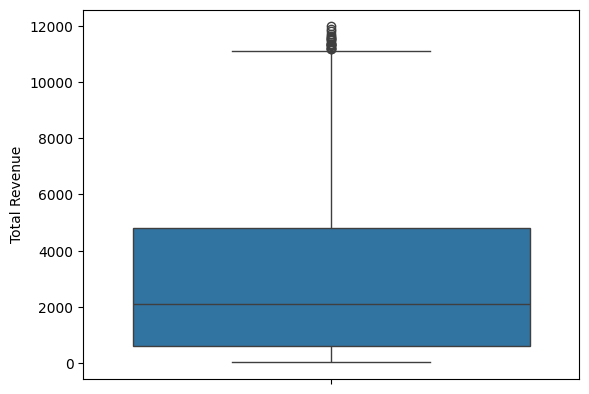

In [187]:
sns.boxplot(x['Total Revenue'])

In [200]:
x.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 29 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             7043 non-null   str    
 1   Age                                7043 non-null   uint8  
 2   Married                            7043 non-null   str    
 3   Number of Dependents               7043 non-null   uint8  
 4   Number of Referrals                7043 non-null   uint8  
 5   Tenure in Months                   7043 non-null   uint8  
 6   Offer                              7043 non-null   str    
 7   Phone Service                      7043 non-null   uint8  
 8   Avg Monthly Long Distance Charges  7043 non-null   float32
 9   Multiple Lines                     7043 non-null   str    
 10  Internet Service                   7043 non-null   uint8  
 11  Internet Type                      7043 non-null   str    
 12  Avg

In [202]:
x.drop(['Churn Category','Churn Reason'],axis=1,inplace=True)
x.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 27 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             7043 non-null   str    
 1   Age                                7043 non-null   uint8  
 2   Married                            7043 non-null   str    
 3   Number of Dependents               7043 non-null   uint8  
 4   Number of Referrals                7043 non-null   uint8  
 5   Tenure in Months                   7043 non-null   uint8  
 6   Offer                              7043 non-null   str    
 7   Phone Service                      7043 non-null   uint8  
 8   Avg Monthly Long Distance Charges  7043 non-null   float32
 9   Multiple Lines                     7043 non-null   str    
 10  Internet Service                   7043 non-null   uint8  
 11  Internet Type                      7043 non-null   str    
 12  Avg

<Axes: ylabel='Population'>

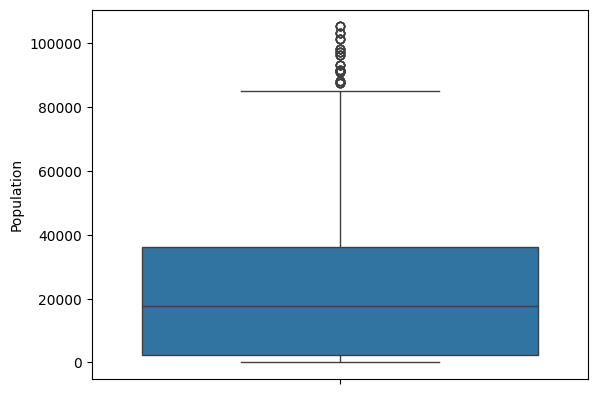

In [206]:
sns.boxplot(x['Population'])

In [208]:
x.describe()

,Age,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Internet Service,Avg Monthly GB Download,Monthly Charge,Total Revenue,Population
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,46.509726,0.468692,1.951867,32.386767,0.903166,22.958954,0.783331,20.515405,63.596134,3034.379056,22139.603294
std,16.750352,0.962802,3.001199,24.542061,0.295752,15.448113,0.412004,20.418940,31.204744,2865.204542,21152.392837
min,19.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,-10.000000,21.360000,11.000000
25%,32.000000,0.000000,0.000000,9.000000,1.000000,9.210000,1.000000,3.000000,30.400000,605.610000,2344.000000
50%,46.000000,0.000000,0.000000,29.000000,1.000000,22.889999,1.000000,17.000000,70.050003,2108.640000,17554.000000
75%,60.000000,0.000000,3.000000,55.000000,1.000000,36.395000,1.000000,27.000000,89.750000,4801.145000,36125.000000
max,80.000000,9.000000,11.000000,72.000000,1.000000,49.990002,1.000000,85.000000,118.750000,11979.340000,105285.000000


In [ ]:
# cols_to_scale = [
# 'Age',
# 'Number of Dependents',
# 'Number of Referrals',
# 'Tenure in Months',
# 'Avg Monthly Long Distance Charges',
# 'Avg Monthly GB Download',
# 'Monthly Charge',
# 'Total Revenue',
# 'Population'
# ]

# from sklearn.preprocessing import StandardScaler

# # Step 1: convert the columns to float first (uint8 can't hold decimals or negatives)
# x[cols_to_scale] = x[cols_to_scale].astype('float64')
# x[cols_to_scale] = x[cols_to_scale].astype('float64')

# # Step 2: create the scaler
# scaler = StandardScaler()

# # Step 3: learn the average and spread from the TRAINING data only, and scale it
# x[cols_to_scale] = scaler.fit_transform(x[cols_to_scale])

# # Step 4: scale the test data using the training average and spread (no fit here)
# x[cols_to_scale] = scaler.transform(x[cols_to_scale])